In [1]:
import h2py
import demes
import demesdraw
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.transforms import ScaledTranslation
import msprime
import numpy as np
import pickle
import pandas


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [2]:
with open("../../statistics/main/bherer_stats.pkl", "rb") as fin:
    data = pickle.load(fin)
data["pops"] = data["pop_ids"]
data["bins"] = h2py.parsing._get_bin_tuples(data["bins"])


def get_H_arrs(data):
    """
    `data` is a dictionary of statistics
    """
    n_pops = len(data["pops"])
    means = np.full((n_pops, n_pops), np.nan)
    idx = 0
    for ii in range(n_pops):
        for jj in range(ii, n_pops):
            means[jj, ii] = data["means"][-1][idx]
            idx += 1
    if "varcovs" in data:
        idx = 0
        stds = np.full((n_pops, n_pops), np.nan)
        for ii in range(n_pops):
            for jj in range(ii, n_pops):
                stds[jj, ii] = data["varcovs"][-1][idx, idx] ** 0.5
                idx += 1
        ret = (means, stds)
    else: 
        ret = means
    return ret


pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
data = h2py.parsing.subset_data(data, to_pops=pops)
graph = "../../models/main/full_model_bherer.yaml"
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=data["bins"], sampled_demes=pops)
E_H_arr = model.h_matrix()
for ii in range(len(pops)):
    for jj in range(len(pops)):
        if jj > ii:
            E_H_arr[ii, jj] = np.nan
H_arr, H_stds = get_H_arrs(data)
scale = 1e3
E_H_arr *= scale
H_arr *= scale
H_stds *= scale
H_residuals = (E_H_arr - H_arr) / H_stds

In [3]:
def compute_F2(Hs):
    stats = h2py.stats.H2stats([Hs], pops=list(range(8)))
    F2 = []
    for ii in range(8):
        for jj in range(ii + 1, 8):
            F2.append(stats.f2(ii, jj))
    return np.array(F2)   


def get_block_F2(input_fname):
    with open(input_fname, "rb") as fin:
        raw_data = pickle.load(fin)
    block_F2s = {}
    for block in raw_data:
        block_L = raw_data[block]["denoms"][-1]
        block_H = raw_data[block]["sums"][-1]
        Hs = block_H / block_L
        Hs = h2py.parsing._subset_means([Hs], raw_data[block]["pop_ids"], pops)[0]
        block_F2 = compute_F2(Hs)
        block_F2s[",".join([str(x) for x in block])] = {"sums": [block_F2 * block_L], "denoms": [block_L]}
    return block_F2s


def get_F2_matrix(data, pops):
    """
    turn a flat array of F2s into a 2dim array.
    """
    n_pops = len(pops)
    matrix = np.full((n_pops, n_pops), np.nan)
    idx = 0
    for ii in range(n_pops):
        for jj in range(ii + 1, n_pops):
            matrix[jj, ii] = data[idx]
            idx += 1
    return matrix


E_F2 = compute_F2(model.data[-1]) 
E_F2_arr = get_F2_matrix(E_F2, model.pops)

# mean observed F2
F2 = compute_F2(data["means"][-1]) 
F2_arr = get_F2_matrix(F2, data["pops"])

block_F2s = get_block_F2("../../statistics/main/bherer_weighted_raw_sums.pkl")
samples = h2py.parsing.get_bootstrap_replicates(block_F2s)
F2_stds = np.std(samples, axis=0)[0]
F2_std_arr = get_F2_matrix(F2_stds, data["pops"])


scale = 1e4
E_F2_arr *= scale
F2_arr *= scale
F2_std_arr *= scale
F2_residuals = (E_F2_arr - F2_arr) / F2_std_arr

In [4]:
"""
Predicting IICR curves. This takes a few minutes
"""


def send_end_times_to_zero(graph, targets):
    builder = graph.asdict()
    for deme in builder["demes"]:
        if deme["name"] in targets:
            deme["epochs"][-1]["end_time"] = 0
    builder = demes.Builder.fromdict(builder)
    return builder.resolve()


def compute_icr(graph, times, samples):
    demog = msprime.Demography.from_demes(graph)
    debug = demog.debug()
    rates, _ = debug.coalescence_rate_trajectory(times, samples)
    return rates


def compute_rccr(graph, times, sample0, sample1):
    demog = msprime.Demography.from_demes(graph)
    debug = demog.debug()
    rates00, _ = debug.coalescence_rate_trajectory(ts, {sample0: 2})
    rates11, _ = debug.coalescence_rate_trajectory(ts, {sample1: 2})
    rates12, _ = debug.coalescence_rate_trajectory(ts, {sample0: 1, sample1: 1})
    return traj


_icr_cache = {}


sample_times = {
    "Altai": 1.15e5,
    "Vindija": 4.5e4,
    "Chagyrskaya": 5.5e4,
    "Denisova": 6e4,
    "Stuttgart": 7e3, 
    "Loschbour": 8e3,
    "UstIshim": 4.5e4,
    "Yoruba1": 0
}

samples = list(sample_times.keys())


graph = demes.load("../../models/main/full_model_bherer.yaml")
zeroed_graph = send_end_times_to_zero(graph, samples)
demog = msprime.Demography.from_demes(zeroed_graph)
debug = demog.debug()
times_in_years = np.logspace(np.log10(5e3), np.log10(3e6), 100)
times = times_in_years / 29
icrs = {}

for sample in samples:
    if sample in _icr_cache:
        icrs[sample] = _icr_cache[sample]
    else:
        sample_cfg = {sample: 2}
        icr, _ = debug.coalescence_rate_trajectory(times, sample_cfg)
        min_time = sample_times[sample]
        icr[times_in_years < min_time] = np.nan
        _icr_cache[sample] = icr
        icrs[sample] = icr

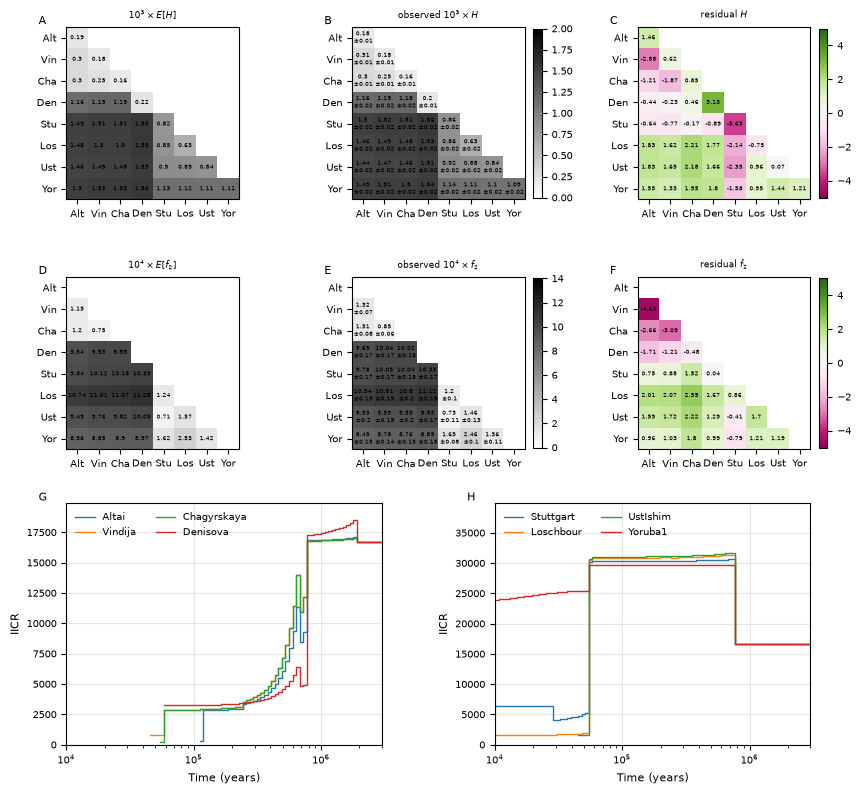

In [7]:

def annotate(ax, data, stds=None, skip=0):
    for ii in range(len(pops)):
        for jj in range(ii + skip, len(pops)):
            if stds is None:
                txt = np.round(data[jj, ii], 2)
            else:        
                xx = np.round(data[jj, ii], 2)
                ci = np.round(stds[jj, ii] * 1.96, 2)
                txt = f"{xx}\n $\\pm${ci}"
            ax.text(ii, jj, txt, ha="center", va="center", color="black", size=4.5)
    return



def label_axs(fig, axs):
    # label mosaic subplots 
    for label, ax in axs.items():
        ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
            ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))
    return



mosaic = "AABBCC;DDEEFF;GGGHHH"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 8), layout="constrained")
cmap = "binary"


#### H
im = axs["A"].imshow(E_H_arr, cmap=cmap, vmin=0, vmax=2)
axs["A"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["A"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["A"].set_title("$10^3 \\times E[H]$")

im = axs["B"].imshow(H_arr, cmap=cmap, vmin=0, vmax=2)
fig.colorbar(im, shrink=0.7)
axs["B"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["B"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["B"].set_title("observed $10^3 \\times H$")

im = axs["C"].imshow(H_residuals, cmap="PiYG", vmin=-5, vmax=5)
fig.colorbar(im, shrink=0.7)
axs["C"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["C"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["C"].set_title("residual $H$")

annotate(axs["A"], E_H_arr)
annotate(axs["B"], H_arr, stds=H_stds)
annotate(axs["C"], H_residuals)


##### F2
cmap = "binary"
vmax = 14

im = axs["D"].imshow(E_F2_arr, cmap=cmap, vmin=0, vmax=vmax)
axs["D"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["D"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["D"].set_title("$10^4 \\times E[f_2]$")

im = axs["E"].imshow(F2_arr, cmap=cmap, vmin=0, vmax=vmax)
fig.colorbar(im, shrink=0.7)
axs["E"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["E"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["E"].set_title("observed $10^4 \\times f_2$")

im = axs["F"].imshow(F2_residuals, cmap="PiYG", vmin=-5, vmax=5)
fig.colorbar(im, shrink=0.7)
axs["F"].set_xticks(range(len(pops)), [pop[:3] for pop in pops])
axs["F"].set_yticks(range(len(pops)), [pop[:3] for pop in pops])
axs["F"].set_title("residual $f_2$")



annotate(axs["D"], E_F2_arr, skip=1)
annotate(axs["E"], F2_arr, stds=F2_std_arr, skip=1)
annotate(axs["F"], F2_residuals, skip=1)


#### IICR
ax = axs["G"]
ax.grid(axis="both", alpha=0.3)
for sample in samples[:4]:
    iicr = 1 / (2 * icrs[sample])
    ax.step(times_in_years, iicr, label=sample, lw=1)
ax.legend(framealpha=0, ncols=2, loc="upper left")
ax.set_ylim(0, 1.99e4)
ax.set_xlim(1e4, times_in_years[-1])
ax.set_xscale("log")
ax.set_xlabel("Time (years)")
ax.set_ylabel("IICR")


ax = axs["H"]
ax.grid(axis="both", alpha=0.3)
for sample in samples[4:]:
    iicr = 1 / (2 * icrs[sample])
    ax.step(times_in_years, iicr, label=sample, lw=1)
ax.legend(framealpha=0, ncols=2, loc="upper left")
ax.set_ylim(0, 3.99e4)
ax.set_xlim(1e4, times_in_years[-1])
ax.set_xscale("log")
ax.set_xlabel("Time (years)")
ax.set_ylabel("IICR")


label_axs(fig, axs)
plt.savefig("../../figures/one_locus_predictions.pdf")